# ICT4SM Laboratory 1 
Group 11 

In [1]:
! pip3 install --user "pymongo"

In [2]:
!pip install holidays

In [3]:
%pip install pymongo folium

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pymongo as pm
from pprint import pprint
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timezone
import os
import pickle
import matplotlib.dates as mdates
import holidays
import folium
from folium import FeatureGroup
from folium.plugins import FastMarkerCluster
from html import escape
from folium.plugins import HeatMap
from folium.plugins import PolyLineTextPath
from pyproj import Transformer

In [5]:
client = pm.MongoClient(
    'bigdatadb.polito.it',
    ssl=True,
    authSource='carsharing',
    username='ictts',
    password='Ict4SM22!',
    tlsAllowInvalidCertificates=True
)

In [6]:
db = client['carsharing']
pb_coll = db['PermanentBookings']
ab_coll = db['ActiveBookings']
pp_coll = db['PermanentParkings']
ap_coll = db['ActiveParkings']

# Step 1 : Preliminary data analysis

## How much data are present in each collection

In [7]:
pb_coll.count_documents({})

28180508

In [8]:
ab_coll.count_documents({})

8743

In [9]:
pp_coll.count_documents({})

28312676

In [10]:
ap_coll.count_documents({})

4790

## For which cities the system is collecting data?

In [11]:
pb_coll.distinct("city")

['Amsterdam',
 'Austin',
 'Berlin',
 'Calgary',
 'Columbus',
 'Denver',
 'Firenze',
 'Frankfurt',
 'Hamburg',
 'Madrid',
 'Milano',
 'Montreal',
 'Munchen',
 'New York City',
 'Portland',
 'Rheinland',
 'Roma',
 'San Diego',
 'Seattle',
 'Stuttgart',
 'Torino',
 'Toronto',
 'Twin Cities',
 'Vancouver',
 'Washington DC',
 'Wien']

## When did each collection start? When did each collection end?

In [12]:
def start_end_collection(coll):
    init = coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)
    end = coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)
    init = next(init)['init_time']
    end = next(end)['final_time']
    return init, end

In [13]:
Init_Time, Final_Time = start_end_collection(pb_coll)
print(Init_Time, Final_Time)

1481650703 1517404383


In [14]:
start_end_collection(ab_coll)

(1512999938, -1)

In [15]:
start_end_collection(pp_coll)

(1481650658, 1517404383)

In [16]:
start_end_collection(ap_coll)

(1516773360, -1)

## What is the total number of cars seen in the whole period in each city? How can you estimate the fleet size in a given period, e.g., one week? How does this relate to the total number of vehicles seen in the whole collection? 

In [17]:
def nbr_distinct_cars(city):
    return print(len(pb_coll.distinct("plate", {"city": city})))

In [18]:
nbr_distinct_cars("Torino")

609


In [19]:
nbr_distinct_cars("Columbus")

215


In [20]:
nbr_distinct_cars("Frankfurt")

304


In [21]:
def weekly_fleet_size(city):
    
    pipeline = [
        {
            "$match": {
                "city": city,
                "init_time": {
                    "$gte": Init_Time,
                    "$lte": Final_Time
                }
            }
        },
        {
            "$group": {
                "_id": {
                    "week": {
                        "$dateTrunc": {
                            "date": {
                                "$toDate": {
                                    "$multiply": ["$init_time", 1000]
                                }
                            },
                            "unit": "week",
                            "startOfWeek": "monday"
                        }
                    },
                    "plate": "$plate"
                }
            }
        },
        {
            "$group": {
                "_id": "$_id.week",
                "nb_plates": {"$sum": 1}
            }
        },
        {
            "$sort": {
                "_id": 1
            }
        }
    ]
    
    weekly = list(pb_coll.aggregate(pipeline))
    df = pd.DataFrame(weekly)
    df.rename(columns={
        "_id": "week",
        "nb_plates": "unique_plates"
    }, inplace=True)

    # Mean (nbr of unique cars by week)
    mean_cars = df["unique_plates"].mean()
    print(f"Mean number of cars per week : {mean_cars:.2f}")

    # Graphique
    plt.figure(figsize=(12, 5))
    plt.plot(df["week"],df["unique_plates"],marker="o",label="Unique cars / week")
    plt.axhline(mean_cars,linestyle="--",label=f"Mean : {mean_cars:.1f}" )
    
    plt.xlabel("Week")
    plt.ylabel("Number of unique cars")
    plt.title("Number of unique cars per week")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    
    plt.show()
    
    return df

Mean number of cars per week : 391.23


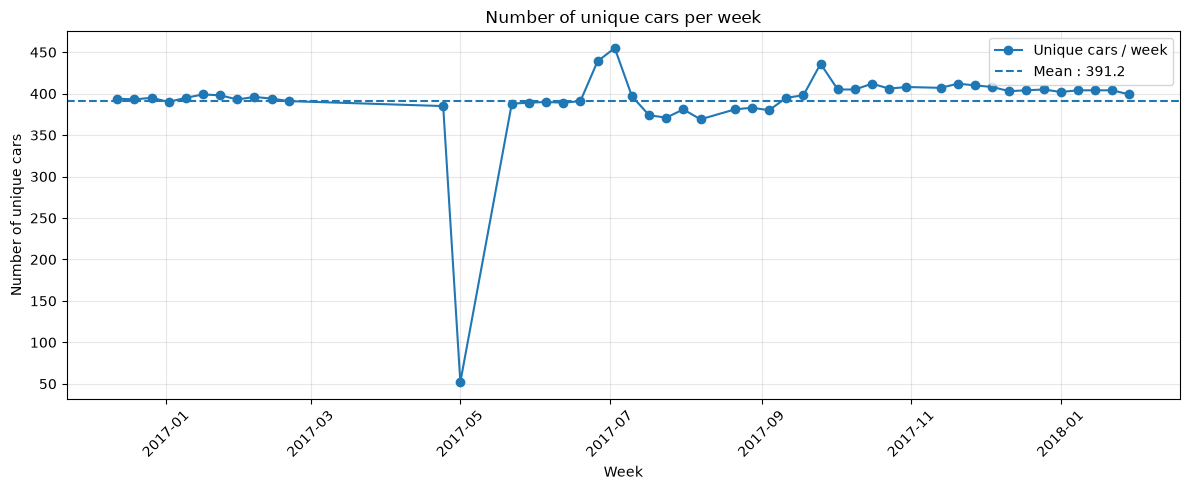

,week,unique_plates
0,2016-12-12,394
1,2016-12-19,393
2,2016-12-26,395
3,2017-01-02,390
4,2017-01-09,395
5,2017-01-16,399
6,2017-01-23,398
7,2017-01-30,393
8,2017-02-06,396
9,2017-02-13,394


In [22]:
weekly_fleet_size("Torino")

Mean number of cars per week : 186.35


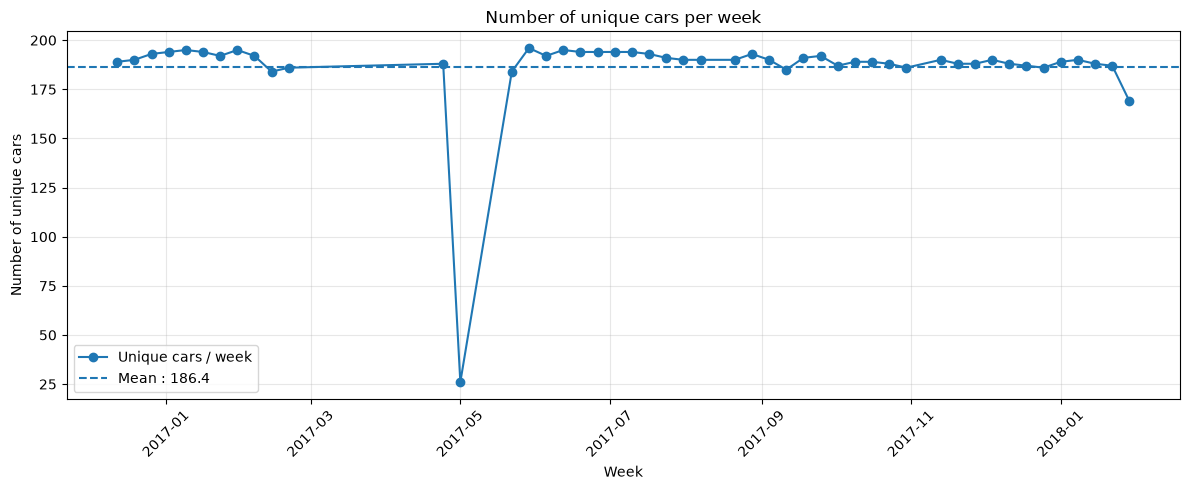

,week,unique_plates
0,2016-12-12,189
1,2016-12-19,190
2,2016-12-26,193
3,2017-01-02,194
4,2017-01-09,195
5,2017-01-16,194
6,2017-01-23,192
7,2017-01-30,195
8,2017-02-06,192
9,2017-02-13,184


In [23]:
weekly_fleet_size("Columbus")

Mean number of cars per week : 240.10


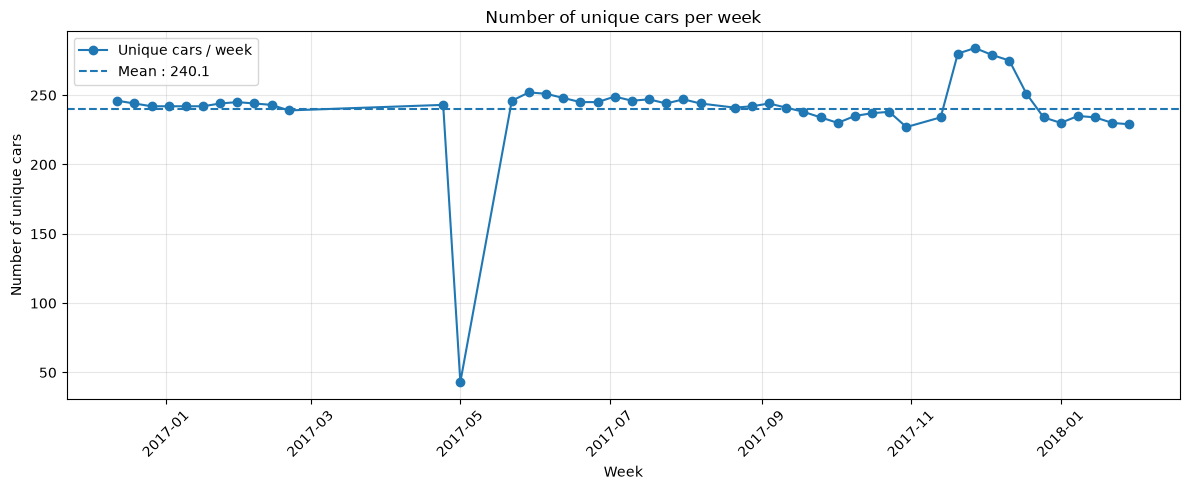

,week,unique_plates
0,2016-12-12,246
1,2016-12-19,244
2,2016-12-26,242
3,2017-01-02,242
4,2017-01-09,242
5,2017-01-16,242
6,2017-01-23,244
7,2017-01-30,245
8,2017-02-06,244
9,2017-02-13,243


In [24]:
weekly_fleet_size("Frankfurt")

## How many bookings have been recorded in December 2017 in each city?

In [25]:
pb_turino_dec = pb_coll.count_documents({
    'city': 'Torino',
    'init_date': {
        '$gte': datetime(2017, 11, 30, 23, 0, 0),
        '$lt': datetime(2017, 12, 31, 23, 0, 0)
    }
})
pb_turino_dec

96038

In [26]:
pb_frankfurt_dec = pb_coll.count_documents({
    'city': 'Frankfurt',
    'init_date': {
        '$gte': datetime(2017, 11, 30, 23, 0, 0),
        '$lt': datetime(2017, 12, 31, 23, 0, 0)
}})
pb_frankfurt_dec

53960

In [27]:
pb_columbus_dec = pb_coll.count_documents({
    'city': 'Columbus',
    'init_date': {
        '$gte': datetime(2017, 12, 1, 5, 0, 0), 
        '$lt': datetime(2018, 1, 1, 5, 0, 0)
    }
})
pb_columbus_dec

20769

## How many bookings have the alternative transportation modes recorded in each city?


In [28]:
def nbr_alternativ_transport(city):
    pb_altmode = pb_coll.count_documents({
        'city': city,
        'public_transport.duration': {'$ne': -1},
        'public_transport.distance': {'$ne': -1},
        'public_transport.distance': {'$ne': 0},
        'public_transport.arrival_date': {'$ne': -1},
        'public_transport.arrival_time': {'$ne': -1}
    })
    return pb_altmode

In [29]:
nbr_alternativ_transport('Torino')

261629

In [30]:
nbr_alternativ_transport("Columbus")

0

In [31]:
nbr_alternativ_transport("Frankfurt")

0

In [32]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1}
})
pb_altmode_torino

261629

# Step 2 – Car sharing usage characterization

## Consider each city of your group, and the period of time of November 1st 2017 – January 31st 2018. Consider the time series (city, timestamp, duration, locations).

In [33]:
CITIES = ["Torino", "Columbus", "Frankfurt"]
START = int(datetime(2017, 11, 1, tzinfo=timezone.utc).timestamp())
END = int(datetime(2018, 2, 1, tzinfo=timezone.utc).timestamp())
Q = 0.90

In [34]:
def load_wtime(coll, city, start=START, end=END, PT=False):
    if PT : 
        pipe = [
            {"$match": {"city": city, "init_time": {"$gte": START, "$lt": END},"public_transport.duration": {"$ne": -1},
        "public_transport.distance": {"$ne": -1}
                       }},
            {"$project": {"_id": 0, 
                          "init_time": 1,
                          "duration": {"$subtract": ["$final_time", "$init_time"]},
                          "day":      {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                            "week":     {"$isoWeek": "$init_date"},
                            "iso_year": {"$isoWeekYear": "$init_date"},
                            "dow":      {"$isoDayOfWeek": "$init_date"},
                            "hour":     {"$hour": "$init_date"},
                          "pt_duration": "$public_transport.duration",
                          "pt_distance": "$public_transport.distance"
                         }}           
        ]
    else : 
        pipe = [
        {"$match": {"city": city, "init_time": {"$gte": START, "$lt": END}}},
            {"$project": {
                "_id": 0,
                "init_time": 1,
                "final_time":1,
                "duration": {"$subtract": ["$final_time", "$init_time"]},
                "day": {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                "week": {"$isoWeek": "$init_date"},
                "iso_year": {"$isoWeekYear": "$init_date"},
                "dow": {"$isoDayOfWeek": "$init_date"},
                "hour": {"$hour": "$init_date"},
                "vendor": 1,
                "init_address": 1,
                "final_address": 1,
                "origin_destination": 1,
                "public_transport":1,
                "plate":1
       
            }},
    ]
        
    df = pd.DataFrame(db[coll].aggregate(pipe, allowDiskUse=True))
    df["duration_min"] = df["duration"]/60
    if PT:
        df["pt_duration_min"] = df["pt_duration"]/60
    return df

def best_zone(x, q=Q, log=True, threshold=False,min_duration=1.0):
    x = np.sort(np.asarray(x, dtype=float))
    if threshold:
        x = x[x >= min_duration]
    else : 
        x = x[x >= 0]
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    k = int(np.ceil(q * n))
    t = np.log(x) if log else x
    widths = t[k - 1 :] - t[: n - k + 1]
    i = np.argmin(widths)

    return x[i], x[i + k - 1]

def keep_best_zone(df, q=Q, col="duration_min", log=True,threshold=False):
    a, b = best_zone(df[col].values, q, log,threshold)
    return df[df[col].between(a, b)].copy(), (a, b)

def get_filtered_data(cities=None, start=START, end=END, q=Q,
                      verbose=True,
                      return_extra=False):
    """
    Return (bookings_f, parkings_f) : two dicts {city: DataFrame} filtered
    
    Parameters:
    cities : default = Torino, Columbus, Frankfurt
    start, end : Unix bornd (default : 01/11/2017 - 01/02/2018)
    q : portion of the conserved CDF (default 0.90)
    verbose  : affiche la zone gardée et le nombre de lignes conservées
    return_extra : True = return also {"raw": ..., "zones": ...}
    """
    cities = list(cities) if cities else list(CITIES)

    raw = {
        "bookings": {c: load_wtime("PermanentBookings", c, start, end) for c in cities},
        "parkings": {c: load_wtime("PermanentParkings", c, start, end) for c in cities},
    }

    filtered = {kind: {} for kind in raw}
    zones = {}
    for kind, data in raw.items():
        for c in cities:
            filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], q)
            if verbose:
                a, b = zones[(kind, c)]
                n0, n1 = len(data[c]), len(filtered[kind][c])
                print(f"{kind:9s} {c:10s} zone = [{a:7.1f}, {b:8.1f}] min "
                      f"-> {n1}/{n0} gardés ({n1 / n0:.1%})")

    if return_extra:
        return filtered["bookings"], filtered["parkings"], {"raw": raw, "zones": zones}
    return filtered["bookings"], filtered["parkings"]

In [35]:
bookings_f_0, parkings_f_0 = get_filtered_data(q=1)

bookings  Torino     zone = [    0.7,  47562.3] min -> 264503/264503 gardés (100.0%)
bookings  Columbus   zone = [    0.7,  40062.2] min -> 52976/52976 gardés (100.0%)
bookings  Frankfurt  zone = [    0.7,  48404.4] min -> 146557/146557 gardés (100.0%)
parkings  Torino     zone = [    0.7,   8856.5] min -> 264542/264542 gardés (100.0%)
parkings  Columbus   zone = [    0.7,  13117.5] min -> 52923/52923 gardés (100.0%)
parkings  Frankfurt  zone = [    0.7,   7418.7] min -> 146854/146854 gardés (100.0%)


In [36]:
# Q3 criterion, q=0.9
bookings_f, parkings_f = get_filtered_data()

bookings  Torino     zone = [    0.8,     38.0] min -> 238053/264503 gardés (90.0%)
bookings  Columbus   zone = [    0.8,     44.0] min -> 47679/52976 gardés (90.0%)
bookings  Frankfurt  zone = [    0.8,     60.1] min -> 131902/146557 gardés (90.0%)
parkings  Torino     zone = [    0.8,    410.4] min -> 238088/264542 gardés (90.0%)
parkings  Columbus   zone = [    1.5,   1719.7] min -> 47631/52923 gardés (90.0%)
parkings  Frankfurt  zone = [    0.8,    432.1] min -> 132169/146854 gardés (90.0%)


## Derive the distribution of booking/parking duration and plot them. Show the distributions as empirical Cumulative Distribution Functions (CDF). Which consideration can you derive from the results? 

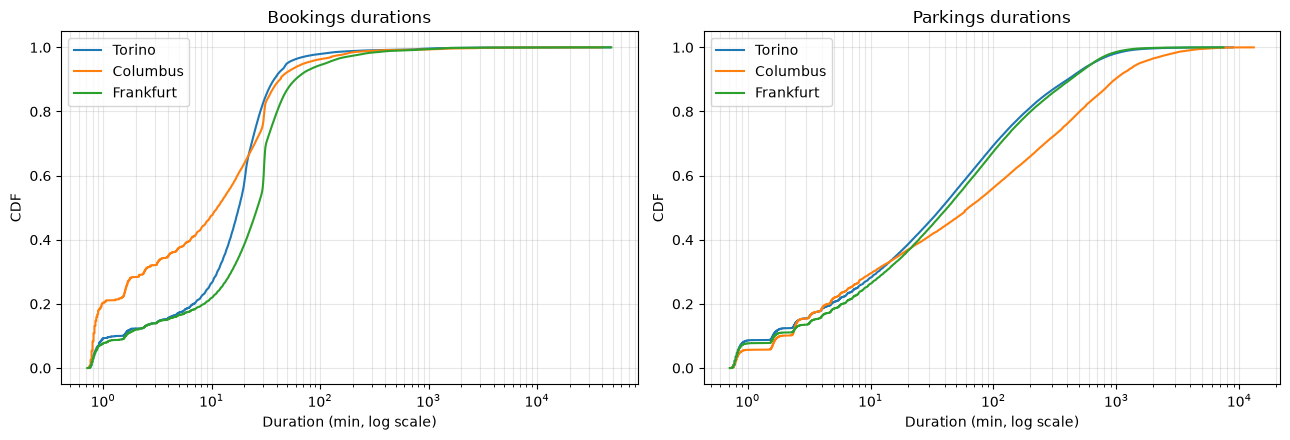

In [37]:
def plot_cdf(data_dict, title, ax):
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        x = x[x > 0]                        # for log axis
        y = np.arange(1, len(x)+1) / len(x)
        ax.plot(x, y, label=city)
    ax.set_xscale("log")
    ax.set_xlabel("Duration (min, log scale)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings_f_0, "Bookings durations", axes[0])
plot_cdf(parkings_f_0, "Parkings durations", axes[1])
plt.tight_layout(); plt.show()

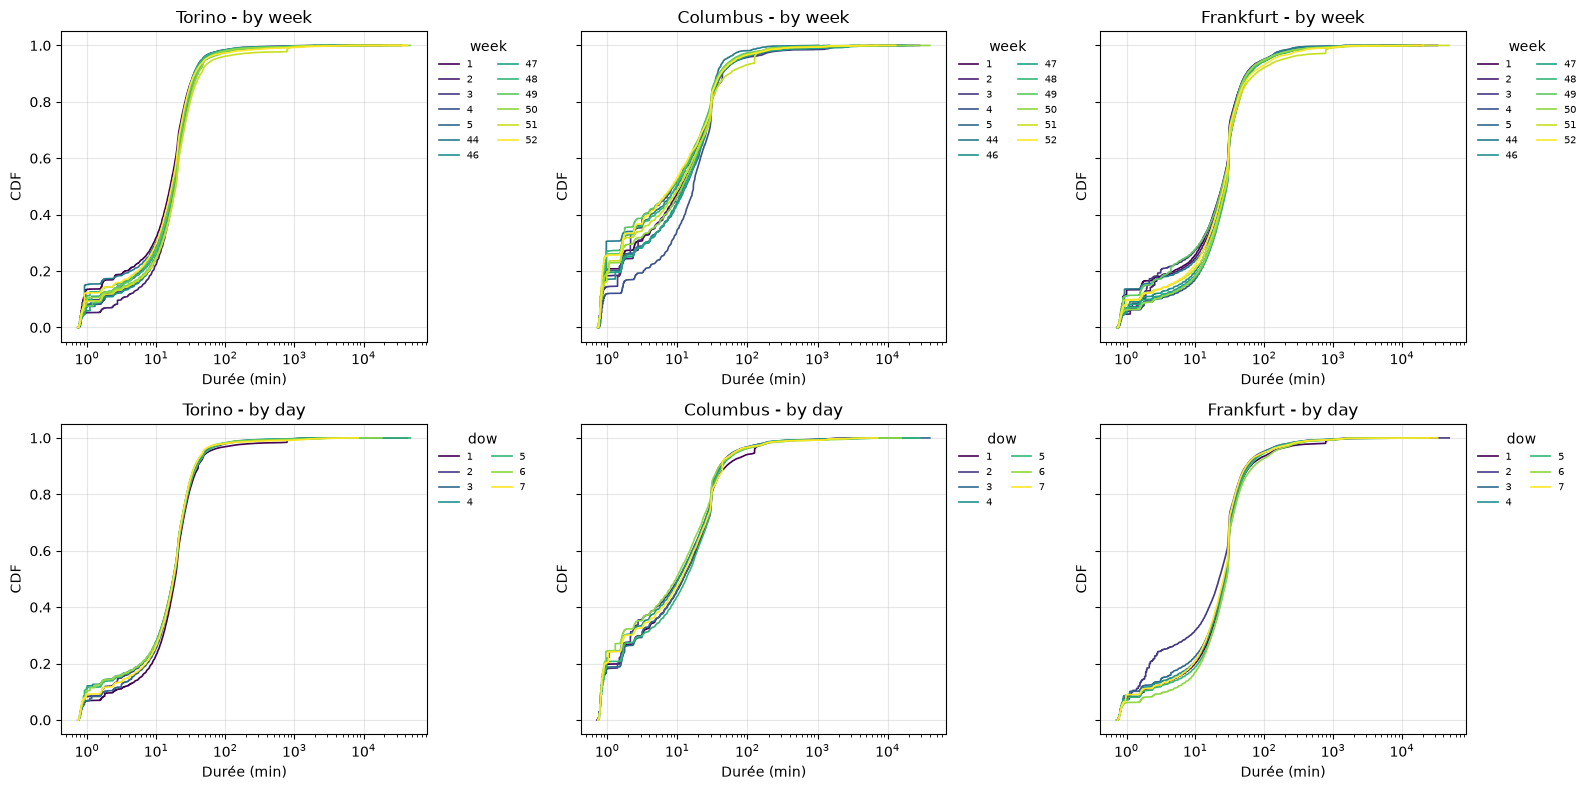

In [38]:
def ecdf(x):
    x = np.sort(np.asarray(x))
    return x, np.arange(1, len(x) + 1) / len(x)


def plot_cdf_by(df, col, ax, title="", cmap="viridis", legend=True,log=False, xmax=None):
    groups = sorted(df[col].unique())
    colors = plt.get_cmap(cmap)(np.linspace(0, 1, len(groups)))
    for c, g in zip(colors, groups):
        x, y = ecdf(df.loc[df[col] == g, "duration_min"])
        ax.plot(x, y, color=c, lw=1.2, label=str(g))

    if log:
        ax.set_xscale("log")
    elif xmax is not None:
        ax.set_xlim(0, xmax) 

    ax.set_xlabel("Durée (min)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(alpha=.3)
    if legend:
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  fontsize=7, ncol=2, frameon=False,
                  title=col)
        

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for j, city in enumerate(CITIES):
    df = pd.DataFrame(bookings_f_0[city]) 

    plot_cdf_by(df, "week", axes[0, j], f"{city} - by week", log=True)
    plot_cdf_by(df, "dow",  axes[1, j], f"{city} - by day", legend=True, log=True)  # too much days for legend

plt.tight_layout()
plt.show()

## Consider the system utilization over time: aggregate rentals per hour of the day, and then plot the number of booked/parked cars (or percentage of booked/parked cars) per hour versus time of day. Do you notice any outliers? Can you explain them?

In [39]:
def fleet_utilization_city(coll,city):
    
    start_ts = datetime(2017, 11, 1, 0, 0, 0)
    end_ts = datetime(2018, 2, 1, 0, 0, 0)

    df = pd.DataFrame(list(coll.find(
        {'city': city,
         "init_date": {
             "$gte": start_ts,
             "$lt": end_ts
         }},
        {
            '_id': 0,
            'init_date': 1,
            'final_date': 1,
            'plate': 1
        }
    )))
    
    # convert the dates
    df['init_date'] = pd.to_datetime(df['init_date'])
    df['final_date'] = pd.to_datetime(df['final_date'])
    
    # keep only valids rentals
    df = df.dropna(subset=['init_date', 'final_date'])
    df = df[df['final_date'] > df['init_date']].copy()
    
    if df.empty:
        raise ValueError("Aucune location valide trouvée pour Torino.")
    
    # nbr of distincts car in pb_coll
    total_cars = df.loc[
        df['plate'].notna() & (df['plate'] != -1),
        'plate'
    ].nunique()
    
    if total_cars == 0:
        raise ValueError("Aucune plaque valide trouvée dans les données.")
    
    hours = pd.date_range(
        df['init_date'].min().floor('h'),
        df['final_date'].max().ceil('h'),
        freq='h',
        inclusive='left'
    )
    
    hourly_rentals = pd.Series({
        hour: (
            (df['init_date'] < hour + pd.Timedelta(hours=1)) &
            (df['final_date'] > hour)
        ).sum()
        for hour in hours
    })
    
    hourly_avg = (
        hourly_rentals.groupby(hourly_rentals.index.hour)
        .mean()
        .reindex(range(24), fill_value=0)
    )
    
    # %of occupied cars
    utilization_pct = hourly_avg / total_cars * 100
    
    print("Nbr of valid rentals :", len(df))
    print("Nbr of distincts cars observed :", total_cars)
    print("Missing values :", utilization_pct.isna().sum())
    print("infinite values :", np.isinf(utilization_pct).sum())
    print(utilization_pct.round(2))
    
    # Graph
    utilization_pct.plot(
        kind='bar',
        figsize=(12, 5),
        rot=0
    )
    
    plt.xlabel('Hour of day')
    plt.ylabel('Booked cars (%)')
    plt.title(f'Average fleet utilization by hour — {city}')
    plt.xticks(range(24))
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()


Nbr of valid rentals : 264672
Nbr of distincts cars observed : 414
Missing values : 0
infinite values : 0
0     35.46
1     26.60
2     18.90
3     15.09
4     16.05
5     16.91
6     21.10
7     35.08
8     60.70
9     58.93
10    50.23
11    49.99
12    57.00
13    56.26
14    56.49
15    59.95
16    61.60
17    64.67
18    67.82
19    68.03
20    57.83
21    44.18
22    39.45
23    40.82
dtype: float64


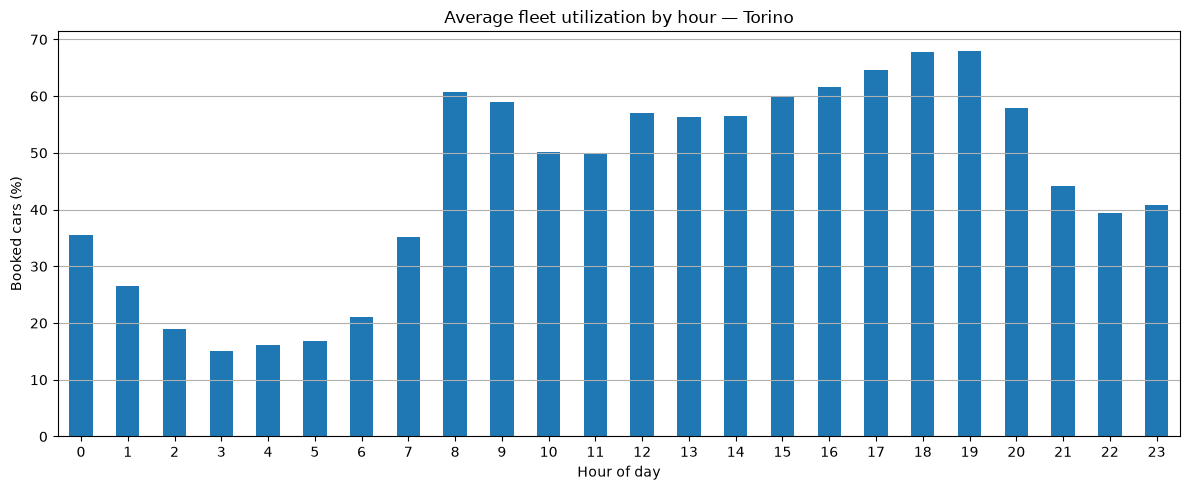

In [40]:
fleet_utilization_city(pb_coll,"Torino")

Nbr of valid rentals : 52885
Nbr of distincts cars observed : 195
Missing values : 0
infinite values : 0
0     17.37
1     11.34
2     10.64
3      9.48
4     12.20
5     15.99
6     15.38
7     20.84
8     30.02
9     27.75
10    24.77
11    24.40
12    24.02
13    25.71
14    26.85
15    28.05
16    29.72
17    31.67
18    26.76
19    23.56
20    20.15
21    19.09
22    17.48
23    16.21
dtype: float64


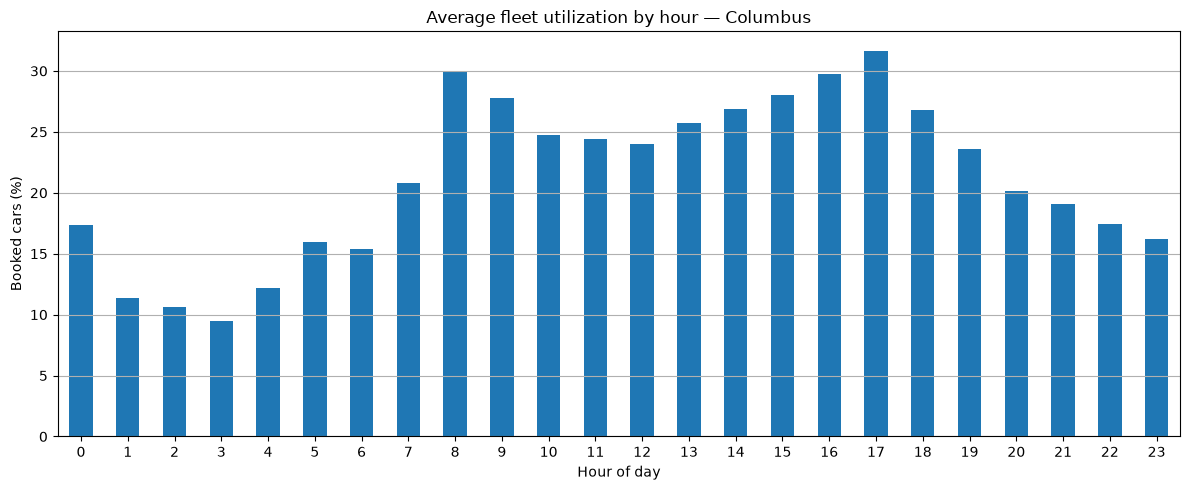

In [41]:
fleet_utilization_city(pb_coll,"Columbus")

Nbr of valid rentals : 146591
Nbr of distincts cars observed : 290
Missing values : 0
infinite values : 0
0     27.08
1     22.10
2     18.82
3     16.75
4     15.58
5     18.77
6     26.82
7     39.61
8     48.06
9     48.61
10    44.96
11    48.03
12    50.18
13    52.49
14    53.44
15    57.71
16    60.69
17    65.62
18    70.23
19    68.13
20    57.56
21    49.29
22    41.87
23    34.33
dtype: float64


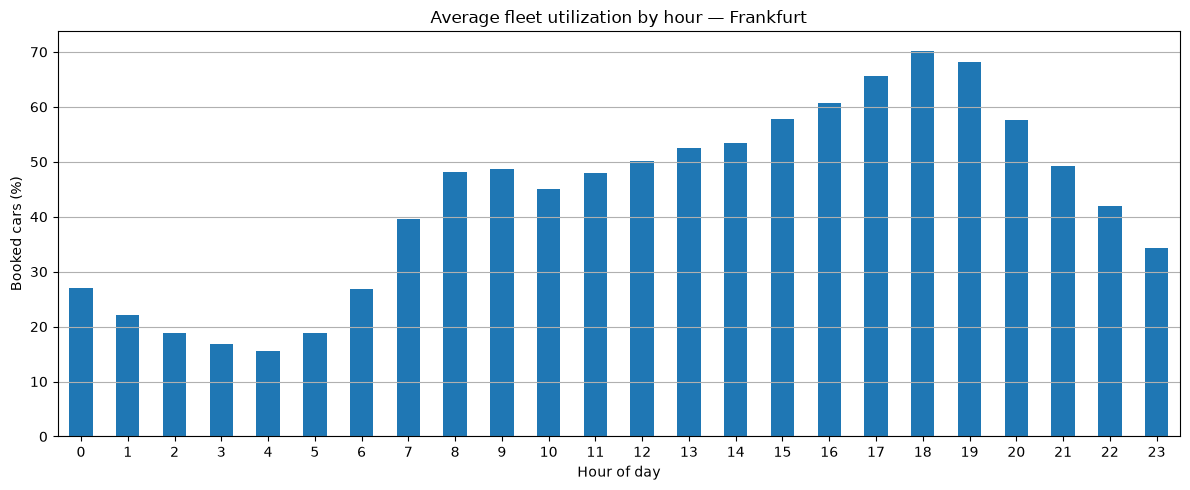

In [42]:
fleet_utilization_city(pb_coll,"Frankfurt")

## Filtering data as above, consider the system utilization over time. How do they change compared to the unfiltered versions? Are you able to filter outliers efficiently for both bookings and parkings? Consider also to plot the CDF of the filtered events. How do these compare to the unfiltered versions?

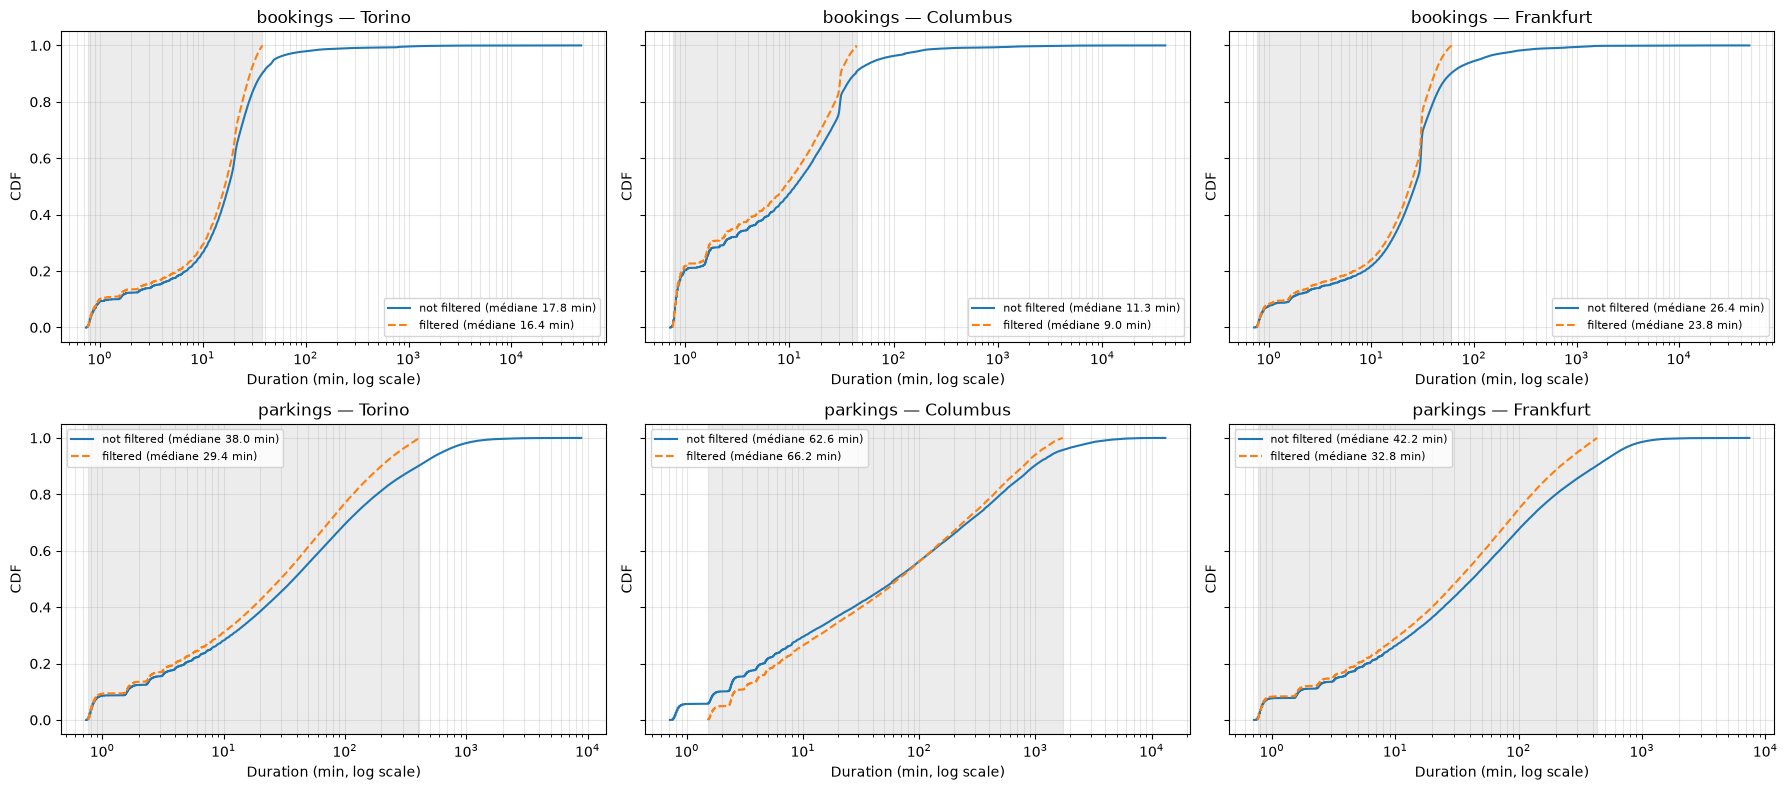

In [43]:
bookings = {c: load_wtime("PermanentBookings", c) for c in CITIES}
parkings = {c: load_wtime("PermanentParkings", c) for c in CITIES}

raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in CITIES:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])

bookings_f = filtered["bookings"]
parkings_f = filtered["parkings"]

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
for r, kind in enumerate(raw):
    for j, c in enumerate(CITIES):
        ax = axes[r, j]
        for df, style, lab in [(raw[kind][c], "-", "not filtered"), (filtered[kind][c], "--", "filtered")]:
            x = np.sort(df["duration_min"].to_numpy())
            x = x[x > 0]
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                    label=f"{lab} (médiane {np.median(x):.1f} min)")
        ax.axvspan(*zones[(kind, c)], color="grey", alpha=0.15)
        ax.set_xscale("log")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Duration (min, log scale)")
        ax.set_ylabel("CDF")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in CITIES:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q, threshold=True)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
for r, kind in enumerate(raw):
    for j, c in enumerate(CITIES):
        ax = axes[r, j]
        for df, style, lab in [(raw[kind][c], "-", "not filtered"), (filtered[kind][c], "--", "filtered")]:
            x = np.sort(df["duration_min"].to_numpy())
            x = x[x > 0]
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                    label=f"{lab} (median {np.median(x):.1f} min)")
        ax.axvspan(*zones[(kind, c)], color="grey", alpha=0.15)
        ax.set_xscale("log")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Duration (min, log scale)")
        ax.set_ylabel("CDF")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
TZ = {"Torino": "Europe/Rome", "Columbus": "America/New_York", "Frankfurt": "Europe/Berlin"}
N_HOURS = (END - START) // 3600

def hourly_occupancy(df):
    d = df[df["duration"] > 0]
    t0 = d["init_time"].to_numpy(dtype=np.int64)
    t1 = t0 + d["duration"].to_numpy(dtype=np.int64)
    s = np.clip((t0 - START) // 3600, 0, N_HOURS)       
    e = np.clip(-((START - t1) // 3600), 0, N_HOURS)    
    diff = np.bincount(s, minlength=N_HOURS + 1) - np.bincount(e, minlength=N_HOURS + 1)
    idx = pd.date_range(pd.Timestamp(START, unit="s", tz="UTC"), periods=N_HOURS, freq="h")
    return pd.Series(np.cumsum(diff)[:N_HOURS], index=idx)

def hour_of_day_profile(occ, city):
    local = occ.tz_convert(TZ[city])
    return local.groupby(local.index.hour).mean()

occ_raw = {k: {c: hourly_occupancy(raw[k][c]) for c in CITIES} for k in raw}
occ_f   = {k: {c: hourly_occupancy(filtered[k][c]) for c in CITIES} for k in raw}

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7), sharex="col")
for r, kind in enumerate(raw):
    for j, c in enumerate(CITIES):
        ax = axes[r, j]
        occ_raw[kind][c].tz_convert(TZ[c]).plot(ax=ax, lw=0.6, label="non filtré")
        occ_f[kind][c].tz_convert(TZ[c]).plot(ax=ax, lw=0.6, alpha=0.8, label="filtré")
        ax.set_title(f"{kind} — {c}")
        ax.set_ylabel("Activ cars / hour")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for r, kind in enumerate(raw):
    for j, c in enumerate(CITIES):
        ax = axes[r, j]
        p_raw = hour_of_day_profile(occ_raw[kind][c], c)
        p_f   = hour_of_day_profile(occ_f[kind][c], c)
        ax.bar(p_raw.index - 0.2, p_raw.values, width=0.4, label="not filtered")
        ax.bar(p_f.index + 0.2, p_f.values, width=0.4, label="filtered")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("local hour")
        ax.set_ylabel("Activ cars mean")
        ax.set_xticks(range(24))
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
rows = []
for kind in raw:
    for c in CITIES:
        n0, n1 = len(raw[kind][c]), len(filtered[kind][c])
        o0, o1 = occ_raw[kind][c].mean(), occ_f[kind][c].mean()
        rows.append({"type": kind, "city": c,
                     "removed events": f"{1 - n1 / n0:.1%}",
                     "mean occupancy (brut)": round(o0, 1),
                     "mean of filtered occupancy": round(o1, 1),
                     "Removed c": f"{1 - o1 / o0:.1%}"})
pd.DataFrame(rows)

## Filtering the data as above, compute the average, median, standard deviation, and percentiles of the booking/parking duration over time (e.g., per each day of the collection).

In [ ]:
def daily_duration_stats(data):
    df = pd.concat(data.values(), ignore_index=True).copy()

    df["init_time"] = pd.to_datetime(df["init_time"], errors="coerce")
    df["duration_min"] = pd.to_numeric(df["duration_min"], errors="coerce")

    df = df.dropna(subset=["init_time", "duration_min"])
    df = df[df["duration_min"] >= 0]

    df["day"] = df["init_time"].dt.date

    stats = df.groupby("day")["duration_min"].agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )

    percentiles = df.groupby("day")["duration_min"].quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95]
    ).unstack()

    percentiles.columns = ["p25", "p50", "p75", "p90", "p95"]

    return stats.join(percentiles)


booking_stats = daily_duration_stats(bookings_f)
parking_stats = daily_duration_stats(parkings_f)

display(booking_stats.head())
display(parking_stats.head())

In [ ]:
def plot_daily_duration_stats_compact(bookings,parkings,cities=None,duration_col="duration_min",percentiles=(10, 25, 75, 90),):
    if cities is None:
        cities = sorted(set(bookings) & set(parkings))
    else:
        cities = list(cities)

    stats = {"bookings": {}, "parkings": {}}
    for kind, datasets in [
        ("bookings", bookings),
        ("parkings", parkings),
    ]:
        for city in cities:
            if city not in datasets:
                print(f"City {city} missing from {kind}, ignored.")
                continue

            df = datasets[city].copy()

            if duration_col not in df.columns:
                raise ValueError(
                    f"Column '{duration_col}' missing for {kind}, {city}"
                )

            if "day" not in df.columns:
                if "init_time" not in df.columns:
                    raise ValueError(
                        f"We need a colums 'day' or 'init_time' "
                        f"for {kind}, {city}"
                    )
                df["day"] = pd.to_datetime(
                    df["init_time"], unit="s", utc=True
                ).dt.strftime("%Y-%m-%d")

            df[duration_col] = pd.to_numeric(
                df[duration_col], errors="coerce"
            )

            df = df[
                df[duration_col].notna()
                & np.isfinite(df[duration_col])
                & (df[duration_col] > 0)
                & df["day"].notna()
            ]

            grouped = df.groupby("day")[duration_col]

            daily = grouped.agg(
                count="count",
                average="mean",
                median="median",
                standard_deviation="std",
            )

            for p in percentiles:
                daily[f"p{p}"] = grouped.quantile(p / 100)

            daily.index = pd.to_datetime(daily.index)
            daily = daily.sort_index()

            stats[kind][city] = daily

            fig, axes = plt.subplots(
                2, 1,
                figsize=(11, 6),
                sharex=True,
                gridspec_kw={"height_ratios": [1, 1.2]},
            )

            fig.suptitle(
                f"{kind.capitalize()} — {city}",
                fontsize=13,
                fontweight="bold",
            )

            axes[0].plot(
                daily.index, daily["average"],
                label="Moyenne",
                color="tab:blue",
                linewidth=1.5,
            )
            axes[0].plot(
                daily.index, daily["median"],
                label="Médiane",
                color="tab:orange",
                linewidth=1.5,
            )

            axes[0].set_ylabel("Durée (min)")
            axes[0].legend(frameon=False, ncol=2)
            axes[0].grid(True, alpha=0.25)

            axes[1].plot(
                daily.index, daily["median"],
                label="Médiane",
                color="tab:orange",
                linewidth=1.5,
            )

            if 25 in percentiles and 75 in percentiles:
                axes[1].fill_between(
                    daily.index,
                    daily["p25"].to_numpy(dtype=float),
                    daily["p75"].to_numpy(dtype=float),
                    color="tab:orange",
                    alpha=0.2,
                    label="P25–P75",
                )

            if 10 in percentiles and 90 in percentiles:
                axes[1].fill_between(
                    daily.index,
                    daily["p10"].to_numpy(dtype=float),
                    daily["p90"].to_numpy(dtype=float),
                    color="tab:pink",
                    alpha=0.2,
                    label="P10–P90",
                )

            axes[1].set_ylabel("Durée (min)")
            axes[1].set_xlabel("Date")
            axes[1].legend(frameon=False, ncol=2)
            axes[1].grid(True, alpha=0.25)

            for ax in axes:
                ax.spines["top"].set_visible(False)
                ax.spines["right"].set_visible(False)

            axes[1].xaxis.set_major_locator(
                mdates.AutoDateLocator(minticks=4, maxticks=8)
            )
            axes[1].xaxis.set_major_formatter(
                mdates.ConciseDateFormatter(
                    axes[1].xaxis.get_major_locator()
                )
            )

            fig.tight_layout()
            plt.show()

    return stats


In [ ]:
daily_stats = plot_daily_duration_stats_compact(
    bookings=bookings_f,
    parkings=parkings_f,
    cities=["Torino", "Columbus", "Frankfurt"],
)

In [ ]:
def plot_daily_duration_stats_holiweekends(bookings,parkings,cities=None,duration_col="duration_min",percentiles=(10, 25, 75, 90),rolling_window=7,show_weekends=True,show_holidays=True,holiday_dates=None,):
    """
    Comparison of weekdays, weekends and holidays
    Detection of unusually long durations

    holiday_dates:
        Optional dict {city: {date: holiday_name}}.
        Dates should use YYYY-MM-DD format.
        Custom dates are added to the automatic calendar
    """

    if cities is None:
        cities = sorted(set(bookings) & set(parkings))

    city_calendars = {
        "turin": ("IT", "TO"),
        "torino": ("IT", "TO"),
        "columbus": ("US", "OH"),
        "frankfurt": ("DE", "HE"),
    }

    holiday_dates = holiday_dates or {}
    stats = {
        "bookings": {},
        "parkings": {},
        "comparison": {"bookings": {}, "parkings": {}},
    }

    for kind, datasets in [
        ("bookings", bookings),
        ("parkings", parkings),
    ]:
        for city in cities:
            df = datasets[city].copy()

            if duration_col not in df.columns:
                raise ValueError(
                    f"Missing '{duration_col}' for {kind}, {city}"
                )

            # Create daily date if necessary
            if "day" not in df.columns:
                if "init_time" not in df.columns:
                    raise ValueError(
                        f"Missing 'day' or 'init_time' for {kind}, {city}"
                    )

                df["day"] = pd.to_datetime(
                    df["init_time"], unit="s", utc=True
                ).dt.strftime("%Y-%m-%d")

            df["day"] = pd.to_datetime(df["day"], errors="coerce").dt.normalize()
            df[duration_col] = pd.to_numeric(
                df[duration_col], errors="coerce"
            )

            df = df[
                df["day"].notna()
                & df[duration_col].notna()
                & np.isfinite(df[duration_col])
                & (df[duration_col] > 0)
            ].copy()

            if df.empty:
                print(f"No valid data for {kind}, {city}")
                continue

            grouped = df.groupby("day")[duration_col]

            daily = grouped.agg(
                count="count",
                average="mean",
                median="median",
                standard_deviation="std",
            )

            for p in percentiles:
                daily[f"p{p}"] = grouped.quantile(p / 100)

            daily = daily.sort_index()

            daily["average_rolling"] = daily["average"].rolling(
                rolling_window, min_periods=1
            ).mean()

            first_year = int(daily.index.min().year)
            last_year = int(daily.index.max().year)
            city_key = city.strip().lower()

            calendar_info = city_calendars.get(city_key)
            if calendar_info:
                country, subdivision = calendar_info
                calendar = holidays.country_holidays(
                    country,
                    subdiv=subdivision,
                    years=range(first_year, last_year + 1),
                )
                holiday_map = {
                    pd.Timestamp(date): name
                    for date, name in calendar.items()
                }
            else:
                holiday_map = {}

            custom = holiday_dates.get(city, {})
            for date, name in custom.items():
                holiday_map[pd.Timestamp(date).normalize()] = name

            daily["is_weekend"] = daily.index.dayofweek >= 5
            daily["holiday"] = [
                holiday_map.get(date, None) for date in daily.index
            ]
            daily["is_holiday"] = daily["holiday"].notna()

            daily["day_type"] = np.select(
                [
                    daily["is_holiday"],
                    daily["is_weekend"],
                ],
                [
                    "Public holiday",
                    "Weekend",
                ],
                default="Weekday",
            )

            stats[kind][city] = daily

            comparison = (
                daily.groupby("day_type")[
                    ["average", "median", "standard_deviation", "count"]
                ]
                .agg(["mean", "median", "count"])
            )

            stats["comparison"][kind][city] = comparison

            print(f"\n{'=' * 60}")
            print(f"{kind.upper()} — {city}")
            print("Daily statistics by day type:")
            print(
                daily.groupby("day_type")[
                    ["average", "median", "standard_deviation"]
                ].mean().round(2)
            )

    return stats


In [ ]:
daily_stats = plot_daily_duration_stats_holiweekends(
    bookings=bookings_f,
    parkings=parkings_f,
    cities=["Torino", "Columbus", "Frankfurt"],
)

## For the City 1 (Torino) of your group, correlate the probability of a rental with the availability of other transport means.

In [ ]:
bookings_fT = load_wtime("PermanentBookings", "Torino", PT=True)
bookings_fT

In [ ]:
step = 5
cap = 120

edges = list(range(0, cap + step, step)) + [np.inf]
labels = [f"{a}-{a+step}" for a in range(0, cap, step)] + [f">{cap}"]
bookings_fT["pt_bin"] = pd.cut(bookings_fT["pt_duration_min"], bins=edges, labels=labels, right=False)

bookings_fT["pt_bin_start"] = pd.cut(bookings_fT["pt_duration_min"], bins=edges,
                            labels=edges[:-1], right=False).astype(float)
counts = bookings_fT["pt_bin"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index.astype(str), counts.values,
              color="#4C78A8", edgecolor="white", width=0.85)
ax.bar_label(bars, fmt="%d", padding=3, fontsize=8)

ax.set_title("Torino : rentals by public transport duration (bins from 5 min)")
ax.set_xlabel("Duration of the public transport journey (min)")
ax.set_ylabel("Number of rentals")
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [ ]:
counts = bookings_fT["pt_bin"].value_counts().sort_index()
prob = counts / counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(prob.index.astype(str), prob.values,
              color="#4C78A8", edgecolor="white", width=0.85)
ax.bar_label(bars, labels=[f"{p:.1%}" for p in prob.values], padding=3, fontsize=8)

ax.set_title("Torino : probability of a rental based on the duration of the journey by public transport")
ax.set_xlabel("duration of the journey by public transport (min)")
ax.set_ylabel("Probability")
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## After filtering the data, consider one city of your collection and check the position of the cars when booked and returned. Then compute the density of cars at rental starting and ending time during different hours of the day.

In [ ]:
collection = bookings_f["Torino"]
print(len(collection))

In [ ]:
def extract_coordinates(geo):
    if not isinstance(geo, dict):
        return pd.Series([None, None, None, None])

    coords = geo.get("coordinates", [])

    if not isinstance(coords, (list, tuple)) or len(coords) == 0:
        return pd.Series([None, None, None, None])

    try:
        depart = coords[0]
        arrivee = coords[-1]

        lon_dep, lat_dep = float(depart[0]), float(depart[1])
        lon_arr, lat_arr = float(arrivee[0]), float(arrivee[1])

        if not (
            -180 <= lon_dep <= 180 and -90 <= lat_dep <= 90
            and -180 <= lon_arr <= 180 and -90 <= lat_arr <= 90
        ):
            return pd.Series([None, None, None, None])

        return pd.Series([lon_dep, lat_dep, lon_arr, lat_arr])

    except (TypeError, ValueError, IndexError):
        return pd.Series([None, None, None, None])


collection[
    ["lon_depart", "lat_depart", "lon_arrivee", "lat_arrivee"]
] = collection["origin_destination"].apply(extract_coordinates)

display(collection[
    ["init_address", "final_address",
     "lon_depart", "lat_depart", "lon_arrivee", "lat_arrivee"]
].head())

In [ ]:
collection_lundi = collection[
    (collection["dow"] == 1) &
    (collection["hour"] >= 8) &
    (collection["hour"] < 10)
].copy()

df_map = collection_lundi.dropna(
    subset=[
        "lon_depart", "lat_depart",
        "lon_arrivee", "lat_arrivee"
    ]
).head(500).copy()

map = folium.Map(
    location=[45.0703, 7.6869],
    zoom_start=13,
    tiles="OpenStreetMap"
)

trajets = FeatureGroup(name="Trips", show=True)

for _, row in df_map.iterrows():

    depart = [row["lat_depart"], row["lon_depart"]]
    arrivee = [row["lat_arrivee"], row["lon_arrivee"]]

    vendor = escape(str(row.get("vendor", "Unknown")))
    adresse_dep = escape(str(row.get("init_address") or "Unknown"))
    adresse_arr = escape(str(row.get("final_address") or "Unknown"))

    folium.PolyLine(
        locations=[depart, arrivee],
        color="blue",
        weight=1,
        opacity=0.5,
        tooltip=f"Trajet — {vendor}",
        popup=folium.Popup(
            f"<b>Vendeur :</b> {vendor}<br>"
            f"<b>Départ :</b> {adresse_dep}<br>"
            f"<b>Arrivée :</b> {adresse_arr}<br>"
            f"<b>Durée :</b> {row.get('duration_min', float('nan')):.2f} min",
            max_width=350
        )
    ).add_to(trajets)

trajets.add_to(map)

if not df_map.empty:
    points = df_map[
        ["lat_depart", "lon_depart"]
    ].values.tolist()

    points += df_map[
        ["lat_arrivee", "lon_arrivee"]
    ].values.tolist()

    map.fit_bounds(points)

folium.LayerControl().add_to(map)

map

In [ ]:
collection_lundi = collection[
    (collection["dow"] == 1) &
    (collection["hour"] >= 8) &
    (collection["hour"] < 10)
].copy()

df_map = collection_lundi.dropna(
    subset=[
        "lon_depart", "lat_depart",
        "lon_arrivee", "lat_arrivee"
    ]
).head(500).copy()

map = folium.Map(
    location=[45.0703, 7.6869],
    zoom_start=13,
    tiles="OpenStreetMap"
)

# Groupe des points
points_depart = FeatureGroup(name="Départs", show=True)
points_arrivee = FeatureGroup(name="Arrivées", show=True)

for _, row in df_map.iterrows():

    depart = [row["lat_depart"], row["lon_depart"]]
    arrivee = [row["lat_arrivee"], row["lon_arrivee"]]

    vendor = escape(str(row.get("vendor", "Unknown")))
    adresse_dep = escape(str(row.get("init_address") or "Unknown"))
    adresse_arr = escape(str(row.get("final_address") or "Unknown"))

    # Point de départ en bleu
    folium.CircleMarker(
        location=depart,
        radius=1,
        color="blue",
        fill=True,
        fill_color="blue",
        fill_opacity=0.6,
        tooltip=f"Départ — {vendor}",
        popup=f"<b>Départ :</b> {adresse_dep}"
    ).add_to(points_depart)

    # Point d'arrivée en rouge
    folium.CircleMarker(
        location=arrivee,
        radius=1,
        color="red",
        fill=True,
        fill_color="red",
        fill_opacity=0.6,
        tooltip=f"Arrivée — {vendor}",
        popup=f"<b>Arrivée :</b> {adresse_arr}"
    ).add_to(points_arrivee)

# Ajout des deux groupes à la carte
points_depart.add_to(map)
points_arrivee.add_to(map)

# Ajustement automatique du zoom
if not df_map.empty:
    points = df_map[
        ["lat_depart", "lon_depart"]
    ].values.tolist()

    points += df_map[
        ["lat_arrivee", "lon_arrivee"]
    ].values.tolist()

    map.fit_bounds(points)

# Contrôle des couches
folium.LayerControl().add_to(map)

map

In [ ]:
collection_lundi = collection[
    (collection["dow"] == 1) &
    (collection["hour"] >=8) &
    (collection["hour"] < 10)
].copy()

df_map = collection_lundi.dropna(
    subset=["lon_depart", "lat_depart", "lon_arrivee", "lat_arrivee"]
).head(200).copy()

map = folium.Map(
    location=[45.0703, 7.6869],
    zoom_start=13,
    tiles="OpenStreetMap"
)

trajets = FeatureGroup(name="Oriented Trips", show=True)

def color_degrade(ratio):
    """Yellow -> red"""
    rouge = 255
    vert = int(255 * (1 - ratio))
    bleu = 0
    return f"#{rouge:02x}{vert:02x}{bleu:02x}"

for _, row in df_map.iterrows():

    depart = [row["lat_depart"], row["lon_depart"]]
    arrivee = [row["lat_arrivee"], row["lon_arrivee"]]

    vendor = escape(str(row.get("vendor", "Unkonown")))
    adresse_dep = escape(str(row.get("init_address") or "Unkonown"))
    adresse_arr = escape(str(row.get("final_address") or "Unkonown"))

    duree = row.get("duration_min", float("nan"))
    try:
        duree_txt = f"{float(duree):.2f} min"
    except (TypeError, ValueError):
        duree_txt = "Unkonown"

    popup = folium.Popup(
        f"<b>Vendeur :</b> {vendor}<br>"
        f"<b>Départ :</b> {adresse_dep}<br>"
        f"<b>Arrivée :</b> {adresse_arr}<br>"
        f"<b>Durée :</b> {duree_txt}",
        max_width=350
    )

    n_segments = 12
    points = [
        [
            depart[0] + (arrivee[0] - depart[0]) * i / n_segments,
            depart[1] + (arrivee[1] - depart[1]) * i / n_segments
        ]
        for i in range(n_segments + 1)
    ]

    for i in range(n_segments):
        ratio = i / (n_segments - 1) if n_segments > 1 else 0
        segment = folium.PolyLine(
            locations=[points[i], points[i + 1]],
            color=color_degrade(ratio),
            weight=3,
            opacity=0.5,
            tooltip=f"Trajet : {vendor}",
            popup=popup if i == 0 else None
        )
        segment.add_to(trajets)

    n = len(points)
    position_fleche = n - 2
    
    ligne_fleche = folium.PolyLine(
        locations=[points[position_fleche], points[-1]],
        color="#222222",
        weight=1,
        opacity=0.01
    ).add_to(trajets)
    
    PolyLineTextPath(
        ligne_fleche,
        "➤",
        repeat=False,
        offset=7,
        attributes={
            "fill": "#222222",
            "font-weight": "bold",
            "font-size": "16"
        }
    ).add_to(trajets)

    folium.CircleMarker(
        location=depart,
        radius=3,
        color="#D6A800",
        fill=True,
        fill_color="#FFFF00",
        fill_opacity=0.9,
        tooltip="Départ"
    ).add_to(trajets)

    folium.CircleMarker(
        location=arrivee,
        radius=3,
        color="#B22222",
        fill=True,
        fill_color="#FF0000",
        fill_opacity=0.9,
        tooltip="Arrivée"
    ).add_to(trajets)

trajets.add_to(map)

if not df_map.empty:
    points_carte = (
        df_map[["lat_depart", "lon_depart"]].values.tolist()
        + df_map[["lat_arrivee", "lon_arrivee"]].values.tolist()
    )
    map.fit_bounds(points_carte)

folium.LayerControl(collapsed=False).add_to(map)

map

In [ ]:
colonnes = [
    "lon_depart", "lat_depart",
    "lon_arrivee", "lat_arrivee"
]

df_map = collection.copy()

for col in colonnes:
    df_map[col] = pd.to_numeric(df_map[col], errors="coerce")

df_map = df_map.dropna(subset=colonnes).head(30).copy()

print("Trajets affichables :", len(df_map))

In [ ]:
transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:32632", always_xy=True
)
m = folium.Map(
    location=[45.0703, 7.6869],
    zoom_start=13,
    tiles="OpenStreetMap"
)


all_lat = pd.concat([
    collection_lundi["lat_depart"],
    collection_lundi["lat_arrivee"]
], ignore_index=True)

all_lon = pd.concat([
    collection_lundi["lon_depart"],
    collection_lundi["lon_arrivee"]
], ignore_index=True)

all_lat = pd.to_numeric(all_lat, errors="coerce").dropna()
all_lon = pd.to_numeric(all_lon, errors="coerce").dropna()

if not all_lat.empty and not all_lon.empty:
    m.fit_bounds([
        [all_lat.min(), all_lon.min()],
        [all_lat.max(), all_lon.max()]
    ])
    
taille_carre = 200  

def compter_par_carre(df, lon_col, lat_col):
    points = df[[lon_col, lat_col]].dropna().copy()

    points["x"], points["y"] = transformer.transform(
        points[lon_col].to_numpy(),
        points[lat_col].to_numpy()
    )

    points["cell_x"] = np.floor(
        points["x"] / taille_carre
    ).astype(int)

    points["cell_y"] = np.floor(
        points["y"] / taille_carre
    ).astype(int)

    return (
        points.groupby(["cell_x", "cell_y"])
        .size()
        .reset_index(name="count")
    )

grid_depart = compter_par_carre(
    collection_lundi, "lon_depart", "lat_depart"
)

grid_arrivee = compter_par_carre(
    collection_lundi, "lon_arrivee", "lat_arrivee"
)

def dessiner_carres(grid, nom, couleur, max_count):
    groupe = folium.FeatureGroup(name=nom, show=True)

    for _, cell in grid.iterrows():
        x_min = int(cell["cell_x"]) * 200
        y_min = int(cell["cell_y"]) * 200

        lon_min, lat_min = transformer.transform(
            x_min, y_min, direction="INVERSE"
        )
        lon_max, lat_max = transformer.transform(
            x_min + 200, y_min + 200, direction="INVERSE"
        )

        n = int(cell["count"])

        ratio = min(n / max_count, 1)
        color = couleur(ratio)

        folium.Rectangle(
            bounds=[[lat_min, lon_min], [lat_max, lon_max]],
            color=color,
            weight=0.5,
            fill=True,
            fill_color=color,
            fill_opacity=1,
            tooltip=f"{nom} : {n} événements"
        ).add_to(groupe)

    groupe.add_to(m)

def couleur_depart(r):
    # yellow to red
    return f"#{int(255):02x}{int(255 * (1-r)):02x}00"

def couleur_arrivee(r):
    rouge = int(220 * (1-r))
    vert = int(235 * (1-r))
    bleu = 255
    return f"#{rouge:02x}{vert:02x}{bleu:02x}"

dessiner_carres(
    grid_depart, "Departures : yellow --> red",
    couleur_depart, max(1, int(grid_depart["count"].max()))
)

dessiner_carres(
    grid_arrivee, "End of trips : light blue --> dark blue",
    couleur_arrivee, max(1, int(grid_arrivee["count"].max()))
)

folium.LayerControl(collapsed=False).add_to(m)

m.fit_bounds([
    [all_lat.min(), all_lon.min()],
    [all_lat.max(), all_lon.max()]
])

display(m)
